# HOG-дескриптор, устойчивый к поворотам изображения

**ФИО студента:** Гришин Никита Андреевич

## Описание задания

**Цель работы:** модифицировать HOG-дескриптор с семинара так, чтобы он стал устойчивым к поворотам изображения, и сравнить его с исходной реализацией

Устойчивость проверяю так: считаю дескриптор исходного изображения и дескриптор этого же изображения, повёрнутого на угол α, и между ними считаю расстояния **L1** и **L2**. Чем ближе вектор повёрнутого изображения к вектору исходного, тем меньше расстояния и тем устойчивее дескриптор к повороту

**Задачи:**
1. Разобрать, почему исходный HOG не инвариантен к повороту.
2. Реализовать модифицированный HOG-дескриптор, устойчивый к поворотам.
3. На нескольких изображениях и при разных углах поворота посчитать L1 и L2 между дескрипторами исходной и повёрнутой версий — для обеих реализаций.
4. Сравнить результаты и сделать выводы.

### Импорты

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage import data, color

pd.set_option("display.precision", 4)
print("OpenCV:", cv2.__version__)

OpenCV: 5.0.0


## Исходная реализация HOG

Код без изменений:

In [2]:
def hog(img, mode = "stats"):
    gx = cv2.Sobel(img, cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(img, cv2.CV_32F, 0, 1)
    mag, ang = cv2.cartToPolar(gx, gy)

    bin_n = 16  # диапазон от 0 до 2pi делится на bin_n частей
    bin = np.int32(bin_n * ang / (2 * np.pi))

    bin_cells = []
    mag_cells = []

    cellx = celly = 8  # Размер ячейки 8x8 пикселей

    for i in range(0, int(img.shape[0] / celly)):
        for j in range(0, int(img.shape[1] / cellx)):
            temp = bin[i * celly : i * celly + celly, j * cellx : j * cellx + cellx] # берем конкретное окно
            values, counts = np.unique(temp.ravel(), return_counts=True) # считаем кол-во значений

            dict_v_c = dict(zip(values, counts))
            dict_c_v = dict(zip(counts, values))

            norm_coef = counts.max()

            if mode == "stats":
                temp_answer = []

                for k in range(bin_n):
                    if k in dict_v_c:
                        temp_answer.append(dict_v_c[k] / norm_coef)
                    else:
                        temp_answer.append(0.0)

                bin_cells.append(temp_answer)
            else:
                bin_cells.append(dict_c_v[norm_coef])

    return np.array(bin_cells).ravel()

### Почему исходный HOG не устойчив к повороту

Если повернуть изображение на угол α, то ломаются сразу две вещи:

1. **Направления градиентов.** Угол градиента `ang` считается от оси x изображения. После поворота у каждого пикселя он становится `ang + α`, то есть вся гистограмма направлений циклически сдвигается на α / (2π / 16) бинов. Дескриптор сравнивает бины по номерам, поэтому даже одинаковые гистограммы, сдвинутые на пару бинов, дают большое расстояние
2. **Пространственная сетка ячеек.** Ячейки 8×8 привязаны к осям изображения. После поворота содержимое ячейки (i, j) переезжает в совсем другую ячейку, а на её место приходит другой кусок картинки. Вектор — это конкатенация гистограмм в фиксированном порядке ячеек, поэтому порядок перемешивается

## Модифицированный HOG-дескриптор

Идея — описывать градиенты не в системе координат изображения, а в системе координат, которая поворачивается вместе с изображением. Для этого беру центр изображения как точку отсчёта

**1. Относительное направление градиента.** Для пикселя с координатами (x, y) считаю полярный угол φ = atan2(y − cy, x − cx) — направление «от центра к пикселю». Вместо абсолютного угла градиента θ беру

$$\theta_{rel} = (\theta - \varphi) \bmod 2\pi$$

При повороте на α и θ, и φ этого пикселя увеличиваются на одно и то же α, поэтому разность не меняется. То есть θ_rel — это направление градиента относительно радиуса, и оно не зависит от поворота

**2. Ячейки-кольца вместо квадратной сетки.** Пиксели группирую не по квадратам 8×8, а по концентрическим кольцам вокруг центра. При повороте вокруг центра пиксель остаётся в том же кольце (расстояние до центра не меняется), поэтому содержимое кольца сохраняется

**3. Круглая область.** Учитываю только пиксели внутри вписанного круга радиуса R. Углы квадратного изображения при повороте уходят за кадр, а внутрь заходят пустые области — внутри круга этого не происходит

**4. Голосование с весом = модуль градиента и мягкое разбиение по бинам.** Каждый пиксель голосует в гистограмму с весом `mag`, а слабые градиенты (< 5% от максимума) не учитываются — так ровные участки и шум не влияют на дескриптор. Голос делится между двумя соседними бинами пропорционально близости к их центрам (линейная интерполяция). Без этого угол около границы бина при небольшом повороте/интерполяции «перепрыгивает» в соседний бин

**5. Сглаживание и нормировка.** Перед вычислением градиентов изображение размываю гауссовым фильтром — это уменьшает влияние интерполяции пикселей при повороте. Гистограмму каждого кольца нормирую по L2, как в классическом HOG

Итоговый вектор: `n_rings × bin_n` = 8 × 16 = 128 значений

In [ ]:
def hog_rotation_invariant(img, bin_n=16, n_rings=8, mag_thr=0.05, border=3):
    img = img.astype(np.float32) / 255.0
    img = cv2.GaussianBlur(img, (5, 5), 1.0) 

    gx = cv2.Sobel(img, cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(img, cv2.CV_32F, 0, 1)
    mag, ang = cv2.cartToPolar(gx, gy)

    # полярные координаты каждого пикселя относительно центра
    h, w = img.shape
    cy, cx = (h - 1) / 2, (w - 1) / 2
    yy, xx = np.mgrid[0:h, 0:w]
    r = np.hypot(xx - cx, yy - cy)
    phi = np.arctan2(yy - cy, xx - cx)
    R = min(h, w) / 2 - border

    # 1. направление градиента относительно радиуса
    rel = np.mod(ang - phi, 2 * np.pi)

    # 3-4. учитываем только пиксели внутри круга и с заметным градиентом
    valid = (r < R) & (mag > mag_thr * mag.max())

    # 4. мягкое разбиение
    pos = rel / (2 * np.pi) * bin_n - 0.5
    b0 = np.floor(pos).astype(int)
    frac = pos - b0
    b0 = b0 % bin_n
    b1 = (b0 + 1) % bin_n

    # 2. номер кольца
    ring = np.minimum((r / R * n_rings).astype(int), n_rings - 1)

    hist = np.zeros((n_rings, bin_n), dtype=np.float64)
    np.add.at(hist, (ring[valid], b0[valid]), mag[valid] * (1 - frac[valid]))
    np.add.at(hist, (ring[valid], b1[valid]), mag[valid] * frac[valid])

    # 5. L2-нормировка гистограммы каждого кольца
    hist /= np.linalg.norm(hist, axis=1, keepdims=True) + 1e-6

    return hist.ravel()

## Данные для экспериментов

Беру 5 стандартных изображений из `skimage.data` — они разные по содержанию: фотограф с камерой, космонавт, чашка кофе, кот и кирпичная стена (повторяющаяся текстура)

Предобработка:
1. Перевожу в оттенки серого
2. Привожу к размеру 256×256
3. Оставляю только вписанный круг, всё снаружи зануляю

Круг нужен, чтобы сравнение было честным: при повороте квадратной картинки углы обрезаются, и тогда повёрнутое изображение содержит другую информацию, а не только повёрнутую исходную

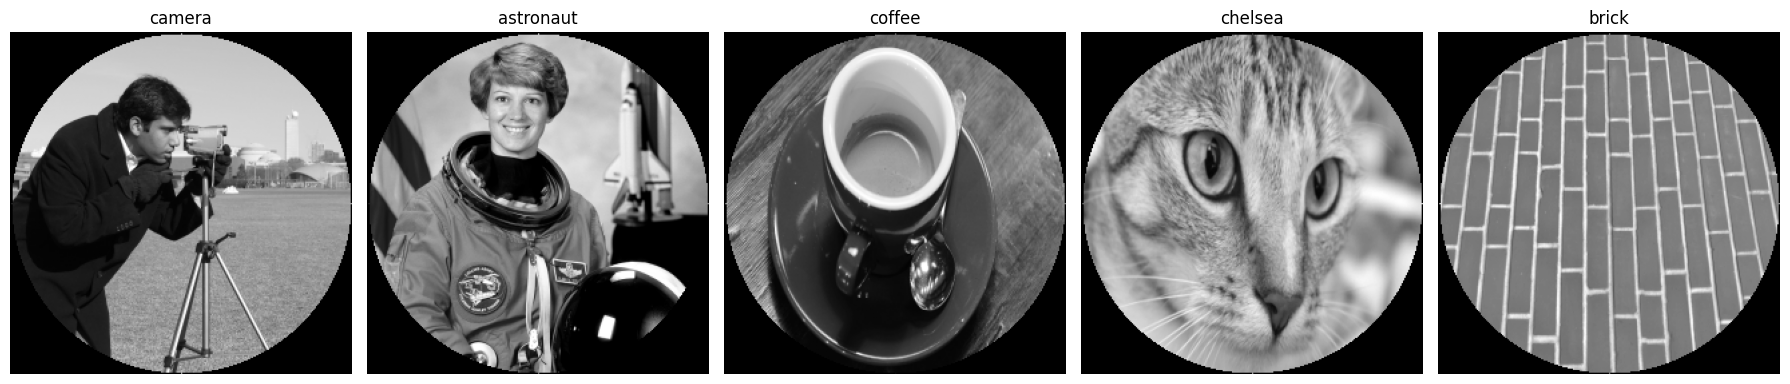

In [13]:
IMG_SIZE = 256

def prepare(img):
    if img.ndim == 3:
        img = color.rgb2gray(img[:, :, :3])
    img = img.astype(np.float32)
    if img.max() <= 1.0:
        img = img * 255
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA).astype(np.uint8)

    mask = np.zeros_like(img)
    cv2.circle(mask, (IMG_SIZE // 2, IMG_SIZE // 2), IMG_SIZE // 2 - 1, 1, -1)
    return img * mask


def rotate(img, angle):
    h, w = img.shape
    M = cv2.getRotationMatrix2D(((w - 1) / 2, (h - 1) / 2), angle, 1.0)
    return cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR)


images = {
    "camera": prepare(data.camera()),
    "astronaut": prepare(data.astronaut()),
    "coffee": prepare(data.coffee()),
    "chelsea": prepare(data.chelsea()),
    "brick": prepare(data.brick()),
}

fig, axes = plt.subplots(1, len(images), figsize=(18, 4))
for ax, (name, img) in zip(axes, images.items()):
    ax.imshow(img, cmap="gray")
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Пример поворотов

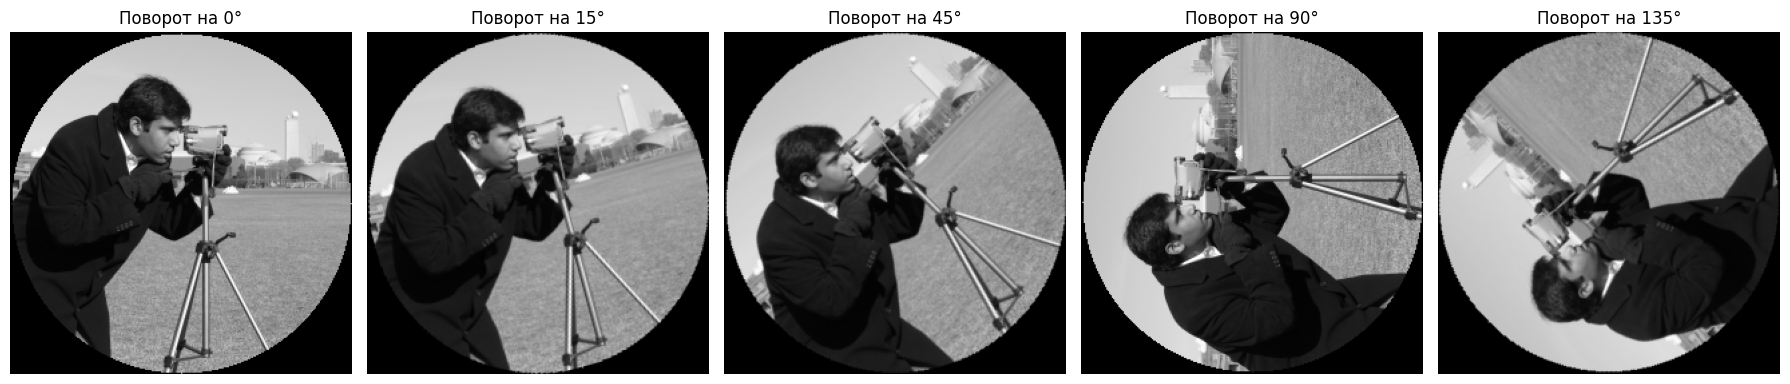

In [5]:
ANGLES = [5, 15, 30, 45, 60, 90, 120, 135, 180, 270]

show_angles = [0, 15, 45, 90, 135]
fig, axes = plt.subplots(1, len(show_angles), figsize=(18, 4))
for ax, a in zip(axes, show_angles):
    ax.imshow(rotate(images["camera"], a), cmap="gray")
    ax.set_title(f"Поворот на {a}°")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Эксперименты: L1 и L2 между исходным и повёрнутым изображением

Для каждого изображения и каждого угла α:
- `d0 = descriptor(img)`, `dα = descriptor(rotate(img, α))`
- **L1** = Σ |d0 − dα|, **L2** = √Σ (d0 − dα)²

У дескрипторов разная длина (исходный — 32·32·16 = 16384, модифицированный — 128) и разная нормировка, поэтому абсолютные L1/L2 сравнивать напрямую не совсем корректно. Поэтому дополнительно считаю **относительные** расстояния: L1 / ‖d0‖₁ и L2 / ‖d0‖₂ — какая доля «длины» вектора поменялась после поворота. Эти величины безразмерные и их можно сравнивать между методами

In [6]:
METHODS = {
    "HOG (семинар)": hog,
    "HOG (модифицированный)": hog_rotation_invariant,
}

def distances(d0, d1):
    diff = d0 - d1
    return dict(
        L1=np.abs(diff).sum(),
        L2=np.linalg.norm(diff),
        L1_rel=np.abs(diff).sum() / np.abs(d0).sum(),
        L2_rel=np.linalg.norm(diff) / np.linalg.norm(d0),
    )

rows = []
for name, img in images.items():
    for method, fn in METHODS.items():
        d0 = fn(img)
        for a in ANGLES:
            d = fn(rotate(img, a))
            rows.append(dict(image=name, method=method, angle=a, **distances(d0, d)))

results = pd.DataFrame(rows)
for method, fn in METHODS.items():
    print(f"{method}: длина дескриптора = {len(fn(images['camera']))}")

HOG (семинар): длина дескриптора = 16384
HOG (модифицированный): длина дескриптора = 128


### Результаты по каждому изображению

In [7]:
SHORT = {"HOG (семинар)": "семинар", "HOG (модифицированный)": "модиф."}

for name in images:
    t = results[results.image == name].pivot(index="angle", columns="method", values=["L1", "L2"])
    t.columns = [f"{metric} {SHORT[m]}" for metric, m in t.columns]
    t = t[["L1 семинар", "L1 модиф.", "L2 семинар", "L2 модиф."]]
    t.index.name = "угол, °"
    print(f"\n=== {name} ===")
    display(t.style.format("{:.4f}"))


=== camera ===


,L1 семинар,L1 модиф.,L2 семинар,L2 модиф.
"угол, °",,,,
5,2856.8653,0.8732,35.8482,0.1073
15,3465.2110,1.0885,41.8608,0.1318
30,3824.2059,1.3162,45.3144,0.1606
45,3944.3495,1.2627,46.3999,0.1591
60,3909.8260,1.0611,46.2684,0.1328
90,4045.2421,0.0000,46.9525,0.0000
120,4167.6182,1.3162,47.9531,0.1606
135,4143.9265,1.2627,47.7256,0.1591
180,4256.8084,0.0000,48.5726,0.0000



=== astronaut ===


,L1 семинар,L1 модиф.,L2 семинар,L2 модиф.
"угол, °",,,,
5,2567.3685,0.6297,35.6401,0.0823
15,3354.5666,0.5842,43.6746,0.0739
30,3565.5364,0.6502,45.7268,0.0824
45,3590.9608,0.7311,45.8020,0.0890
60,3709.2244,0.6892,46.7841,0.0886
90,3773.4724,0.0000,47.2270,0.0000
120,3772.2538,0.6503,47.3556,0.0824
135,3725.8566,0.7310,46.8559,0.0890
180,3701.3958,0.0000,46.5383,0.0000



=== coffee ===


,L1 семинар,L1 модиф.,L2 семинар,L2 модиф.
"угол, °",,,,
5,2208.3979,0.5020,30.6600,0.0591
15,2982.8787,0.5790,39.1163,0.0672
30,3353.9953,0.6495,42.8190,0.0807
45,3627.0217,0.7417,45.2566,0.0879
60,3784.0764,0.6656,46.5166,0.0775
90,4017.3922,0.0000,48.2681,0.0000
120,3868.4820,0.6492,47.2205,0.0806
135,3750.4059,0.7417,46.0315,0.0879
180,3590.0384,0.0000,44.4010,0.0000



=== chelsea ===


,L1 семинар,L1 модиф.,L2 семинар,L2 модиф.
"угол, °",,,,
5,2869.6939,0.6132,37.0161,0.0759
15,3610.1623,0.5947,44.3746,0.0777
30,3842.7968,0.6529,46.3580,0.0804
45,3965.5196,0.6443,47.4984,0.0825
60,4012.5705,0.6296,47.8020,0.0799
90,4116.1439,0.0000,48.3538,0.0000
120,4155.9595,0.6530,48.7255,0.0804
135,4070.1547,0.6444,48.2398,0.0824
180,4136.3132,0.0000,48.7135,0.0000



=== brick ===


,L1 семинар,L1 модиф.,L2 семинар,L2 модиф.
"угол, °",,,,
5,2805.3717,0.5773,36.7694,0.0697
15,3312.1202,0.5339,41.7200,0.0678
30,3575.3188,0.5412,44.9226,0.0645
45,3794.9453,0.6552,46.9856,0.0869
60,3845.0115,0.6600,47.3516,0.0868
90,3657.9317,0.0003,45.3319,0.0002
120,3900.6537,0.5411,47.8712,0.0645
135,3832.0541,0.6551,47.2973,0.0869
180,3347.1840,0.0000,42.1585,0.0000


### Расстояния в зависимости от угла поворота

Ось Y в логарифмическом масштабе — значения у двух методов отличаются на несколько порядков. Для углов 90°, 180°, 270° у модифицированного дескриптора расстояние практически нулевое. Такой поворот — это просто перестановка пикселей без интерполяции, и для модифицированного дескриптора он ничего не меняет

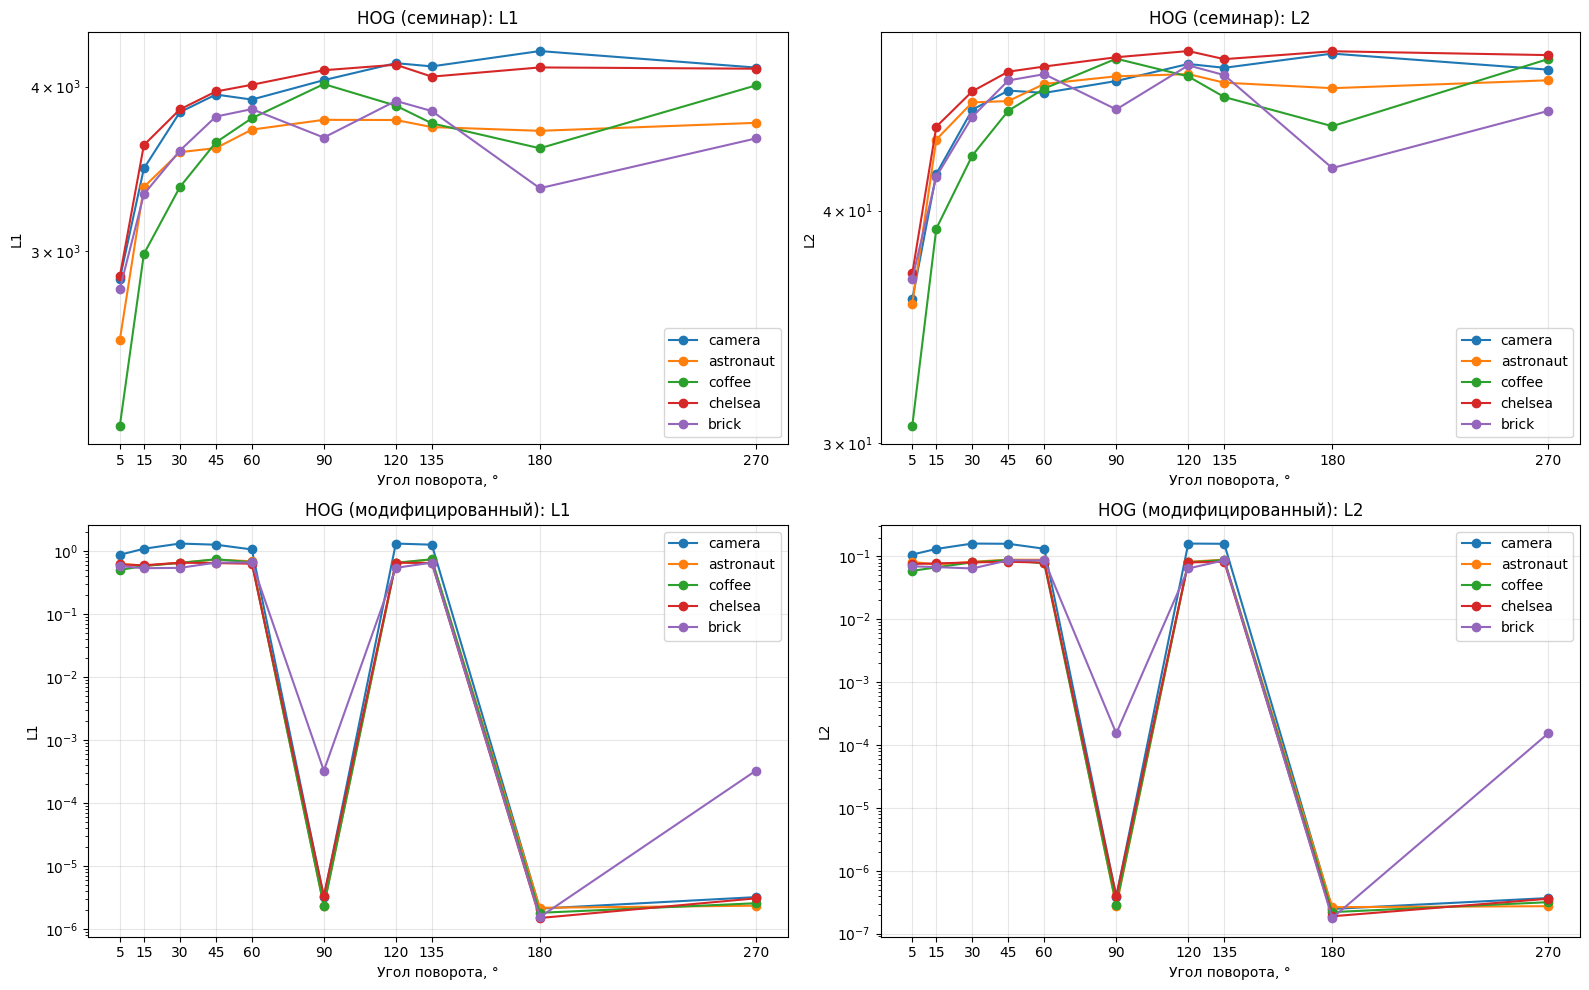

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for col, metric in enumerate(["L1", "L2"]):
    for row, method in enumerate(METHODS):
        ax = axes[row, col]
        for name in images:
            t = results[(results.image == name) & (results.method == method)]
            ax.plot(t.angle, t[metric], marker="o", label=name)
        ax.set_yscale("log")
        ax.set_title(f"{method}: {metric}")
        ax.set_xlabel("Угол поворота, °")
        ax.set_ylabel(metric)
        ax.set_xticks(ANGLES)
        ax.grid(alpha=0.3)
        ax.legend()
plt.tight_layout()
plt.show()

### Относительные расстояния

Сравнение в одном масштабе: какая доля вектора изменилась при повороте

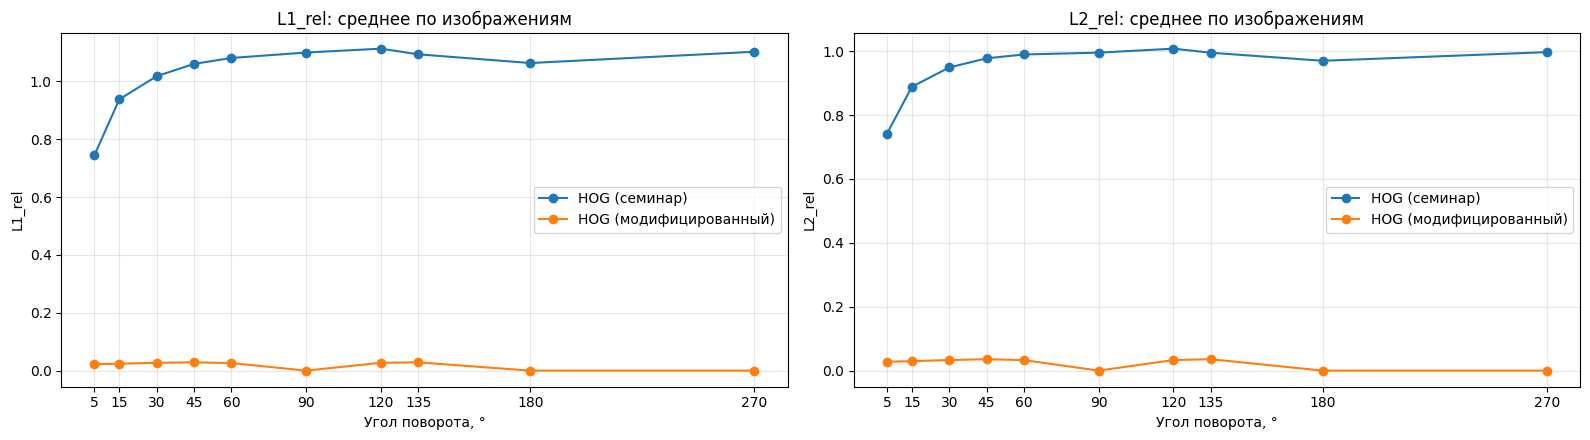

In [14]:
rel = results.groupby(["method", "angle"])[["L1_rel", "L2_rel"]].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, metric in zip(axes, ["L1_rel", "L2_rel"]):
    for method in METHODS:
        t = rel[rel.method == method]
        ax.plot(t.angle, t[metric], marker="o", label=method)
    ax.set_title(f"{metric}: среднее по изображениям")
    ax.set_xlabel("Угол поворота, °")
    ax.set_ylabel(metric)
    ax.set_xticks(ANGLES)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### Проверка различающей способности

Маленькое расстояние между исходным и повёрнутым изображением само по себе ещё ничего не значит: дескриптор, который всегда возвращает нулевой вектор, тоже «идеально инвариантен». Поэтому проверяю, что модифицированный дескриптор по-прежнему различает **разные** изображения: считаю L2 между дескрипторами всех пар изображений и сравниваю с L2 между изображением и его поворотом

In [15]:
names = list(images)
desc = {n: hog_rotation_invariant(images[n]) for n in names}
pair_l2 = pd.DataFrame([[np.linalg.norm(desc[a] - desc[b]) for b in names] for a in names],
                       index=names, columns=names)
display(pair_l2.round(3))

mod = results[results.method == "HOG (модифицированный)"]
off_diag = pair_l2.values[~np.eye(len(names), dtype=bool)]
print(f"L2 между разными изображениями:        min = {off_diag.min():.3f}, среднее = {off_diag.mean():.3f}")
print(f"L2 между изображением и его поворотом: max = {mod.L2.max():.3f}, среднее = {mod.L2.mean():.3f}")

,camera,astronaut,coffee,chelsea,brick
camera,0.000,1.706,2.206,1.934,1.721
astronaut,1.706,0.000,1.914,1.445,1.357
coffee,2.206,1.914,0.000,1.631,1.749
chelsea,1.934,1.445,1.631,0.000,1.224
brick,1.721,1.357,1.749,1.224,0.000


L2 между разными изображениями:        min = 1.224, среднее = 1.689
L2 между изображением и его поворотом: max = 0.161, среднее = 0.065


## Сравнение исходного и модифицированного алгоритмов

In [12]:
summary = results.groupby("method")[["L1", "L2", "L1_rel", "L2_rel"]].agg(["mean", "max"])
display(summary.round(4))

# проверка требования: для каждого изображения и угла модифицированный дескриптор лучше
p = results.pivot_table(index=["image", "angle"], columns="method", values=["L1", "L2"])
ok_l1 = (p["L1"]["HOG (модифицированный)"] < p["L1"]["HOG (семинар)"]).all()
ok_l2 = (p["L2"]["HOG (модифицированный)"] < p["L2"]["HOG (семинар)"]).all()
print(f"L1 модифицированного меньше во всех {len(p)} экспериментах: {ok_l1}")
print(f"L2 модифицированного меньше во всех {len(p)} экспериментах: {ok_l2}")

L1                  L2           L1_rel  \
                             mean        max     mean      max    mean   
method                                                                   
HOG (модифицированный)     0.5194     1.3162   0.0645   0.1606  0.0184   
HOG (семинар)           3681.6676  4256.8084  45.1373  48.7255  1.0315   

                                L2_rel          
                           max    mean     max  
method                                          
HOG (модифицированный)  0.0488  0.0228  0.0568  
HOG (семинар)           1.1963  0.9510  1.0529

L1 модифицированного меньше во всех 50 экспериментах: True
L2 модифицированного меньше во всех 50 экспериментах: True


## Выводы

1. **Исходный HOG с семинара к повороту не устойчив.** Уже при повороте на 5° L2 между дескрипторами исходного и повёрнутого изображения ≈ 31–37, а при 30° и больше выходит на ≈ 45–49. Относительное расстояние L2 / ‖d0‖ в среднем 0.95, то есть после поворота вектор меняется почти целиком — как если бы сравнивались два разных изображения

2. **Итоговое сравнение (5 изображений × 10 углов = 50 экспериментов):**

| Метод | L1 (среднее) | L1 (макс.) | L2 (среднее) | L2 (макс.) | L2 / ‖d0‖ (среднее) |
|---|---|---|---|---|---|
| HOG (семинар) | 3681.7 | 4256.8 | 45.14 | 48.73 | 0.951 |
| HOG (модифицированный) | 0.519 | 1.316 | 0.065 | 0.161 | 0.023 |

Требование задания выполнено: L1 и L2 модифицированного дескриптора меньше, чем у исходного, во всех 50 экспериментах. Так как у дескрипторов разная длина (16384 и 128) и разная нормировка, дополнительно сравнил относительные расстояния: у модифицированного после поворота меняется в среднем ~2% «длины» вектора, у исходного — ~95%. То есть выигрыш есть не только из-за масштаба значений, а по существу

3. **За счёт чего получилась устойчивость.**
   - Направление градиента берётся относительно радиуса (θ − φ) — при повороте оба угла сдвигаются на одно и то же α, разность не меняется
   - Кольца вместо квадратных ячеек — при повороте вокруг центра пиксель остаётся в своём кольце
   - Круглая область — при повороте в неё не заходят пустые углы
   - Взвешивание по модулю градиента, порог на слабые градиенты, мягкое разбиение по бинам и гауссово сглаживание уменьшают влияние интерполяции при повороте

4. **Повороты на 90°, 180°, 270°** дают расстояние ~1e-6, то есть дескриптор совпадает. Такой поворот — это просто перестановка пикселей без интерполяции, и для модифицированного дескриптора он ничего не меняет. Остаточная ошибка при других углах возникает только из-за билинейной интерполяции при повороте. Поэтому, например, расстояния для 30° и 120° (= 30° + 90°), а также для 45° и 135° совпадают

5. **Различающая способность сохранилась.** L2 между дескрипторами разных изображений — от 1.22 до 2.21, а между изображением и его поворотом — не больше 0.161. Разрыв примерно на порядок, так что дескриптор не стал «одинаковым для всего», а именно перестал реагировать на поворот

6. **Ограничения.** Инвариантность достигается за счёт того, что дескриптор описывает область вокруг фиксированного центра (центр поворота) — для поиска объектов это значит, что дескриптор нужно считать в окне, центрированном на объекте. Кроме того, кольца теряют информацию о том, в каком секторе кольца находится градиент, поэтому дескриптор менее детальный, чем исходный HOG